# Exercise 1

- Implement your own version of the line-fitting procedure, using the same data.
- Now try it with the data in `lectures/data/linear_fits/data_1.txt`
    - First plot the data. What has changed?
    - Try the same model and likelihood on the new data. You might want to adjust the prior on $m$ and $b$ for this new data set.
    - What if you use the provided uncertainty per data point $\sigma_{y_i}$, instead of assuming a constant variance $\sigma_y$ for all data points?
    - Instead use the actual likelihood of the data:


\begin{aligned}
\mu(x_i) &= m x_i + b,\\
\sigma(x_i) &= \sigma_{y_i} + f\,\mu(x_i)^2, \qquad f > 0,\\
y_i &\sim \mathcal{N}\!\left(\mu(x_i),\,\sigma(x_i)^2\right).
\end{aligned}


Careful with the normalisation of the Gaussian likelihood. Because we vary the variance, this matters now!

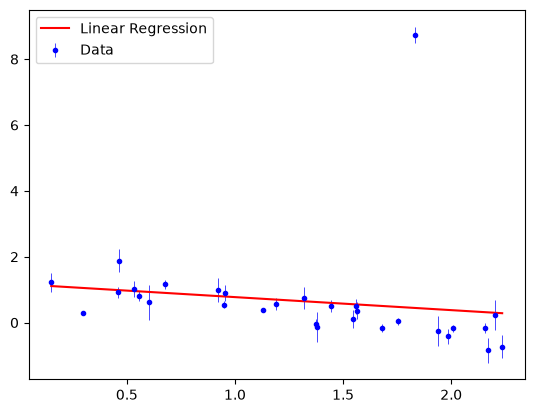

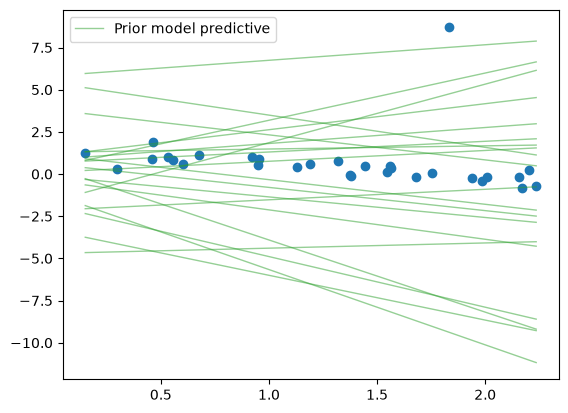

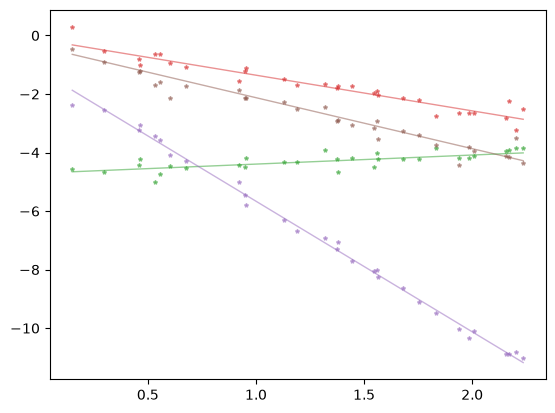

In [157]:
import numpy as np
import scipy.stats as ss
import matplotlib.pyplot as plt

x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_1.txt", unpack=True)

m_rg, b_rg = np.polyfit(x, y, deg=1)

#print(m_rg, b_rg)

plt.errorbar(x, y, yerr=y_err, fmt=".", color="blue", elinewidth=0.5, label="Data")
plt.plot(x, m_rg*x + b_rg, color="red", label="Linear Regression")
plt.legend()



def model(m, b, x):
   return m*x + b

def sigma_y(m, b, x, y_err, f):
   sigma = y_err + f * model(m, b, x)**2
   return sigma


def het_log_likelihood_probability(m, b, x, y, y_err, f):
   prediction = model(m, b, x)

   n = len(y)

   sigma = sigma_y(m, b, x, y_err, f)

   return -0.5 * np.sum((y - prediction)**2/sigma**2) - 0.5*np.sum(np.log(2*np.pi*sigma**2))


# Define Priors for m and b

m_prior = ss.norm(loc=-0.5, scale=3)
b_prior = ss.norm(loc=1, scale=3)
f_prior = ss.norm(loc=0.5, scale= 3)






def het_log_prior(m, b, f):
   return m_prior.logpdf(m) + b_prior.logpdf(b) + f_prior.logpdf(f)


def prior_sampling(n_samples):
   return np.stack((m_prior.rvs(n_samples), b_prior.rvs(n_samples))).T

rng = np.random.default_rng(seed=42)

prior_model_predictive = np.array([model(*parameters, x) for parameters in prior_sampling(n_samples=20)])


fig, ax = plt.subplots(1, 1)

ax.scatter(x,y)
style = dict(c="C2", lw=1, alpha=0.5)
ax.plot(x, prior_model_predictive.T, **style)
ax.plot([], [], label="Prior model predictive", **style)
ax.legend();

prior_predictive = (prior_model_predictive + y_err*rng.normal(size=prior_model_predictive.shape))


pmp_style = dict(lw=1, alpha=0.5)
pp_style = dict(ls="none", marker="*", ms=3, alpha=0.5)


fig, ax = plt.subplots(1, 1)

for i in range(4):
    ax.plot(x, prior_model_predictive[i], c=f"C{i+2}", **pmp_style)
    ax.plot(x, prior_predictive[i], c=f"C{i+2}", **pp_style)




In [158]:
import scipy.optimize as so

def log_posterior(m, b, f, x, y, y_err):
    return het_log_likelihood_probability(m, b, x, y, y_err, f) + het_log_prior(m, b, f)


def negative_log_post(theta, x, y, y_err):
    m, b, f = theta
    return -log_posterior(m, b, f, x, y, y_err)

MAP_result = so.minimize(fun=negative_log_post, x0=(-0.5, 1, 0.5), args=(x, y, y_err), method="BFGS")

m_MAP, b_MAP, f_MAP = MAP_result.x

print("MAP results")
print("m_MAP:", m_MAP)
print("b_MAP:", b_MAP)
print("f_MAP:", f_MAP)


MAP results
m_MAP: 0.46614735337265256
b_MAP: 0.34532789184579427
f_MAP: 1.1644537895372231


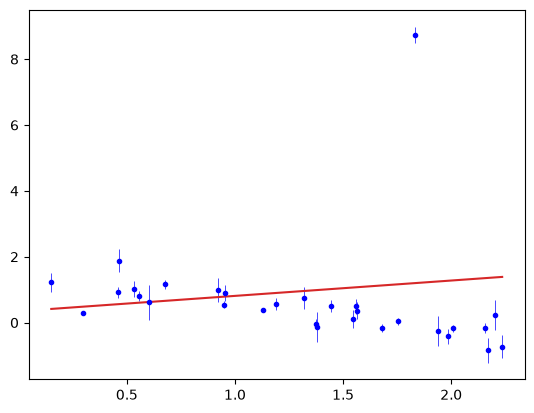

In [159]:
fig, ax = plt.subplots(1,1)


plt.errorbar(x, y, yerr=y_err, fmt=".", color="blue", elinewidth=0.5, label="Data")

ax.plot(x, model(m_MAP, b_MAP, x), c="C3")


In [191]:
import emcee

# emcee passes an array of values for the sampled parameters
# This wrapper just splits the array theta into m and b
def log_posterior_wrapper(theta, x, y_err, y):
    m, b, f = theta
    return log_posterior(m, b, f, x, y, y_err)

# emcee requires some extra settings to run
n_param = 3       # Number of parameter we are sampling
n_walker = 32     # Number of walkers. This just needs to be 
                  # larger than 2*n_param + 1!
n_step = 15000     # How many steps each walker will take. The number
                  # of samples will be n_walker*n_step

# The starting point for each walker
theta_init = MAP_result.x + 0.1*np.random.normal(size=(n_walker, n_param))

sampler = emcee.EnsembleSampler(
    nwalkers=n_walker, ndim=n_param,
    log_prob_fn=log_posterior_wrapper,
    args=(x, y_err, y)
)
state = sampler.run_mcmc(theta_init, nsteps=n_step)


# The samples will be correlated, this checks how correlated they are
# We will discuss this once we come to MCMC methods
print("Auto-correlation time:")
for name, value in zip(["m", "b", "f"], sampler.get_autocorr_time()):
    print(f"{name} = {value:.1f}")

# We need to discard the beginning of the chain (a few auto-correlation times)
# to get rid of the initial conditions
chain = sampler.get_chain(discard=300, thin=10, flat=True)


Auto-correlation time:
m = 75.3
b = 127.0
f = 65.5


In [192]:
print("Posterior results (mean±std)")
print(f"m = {np.mean(chain[:,0]):.2f}±{np.std(chain[:,0]):.2f}")
print(f"b = {np.mean(chain[:,1]):.2f}±{np.std(chain[:,1]):.2f}")
print(f"f = {np.mean(chain[:,2]):.2f}±{np.std(chain[:,2]):.2f}")

#print(chain[0,:])


Posterior results (mean±std)
m = 0.65±0.13
b = -0.54±0.12
f = 3.83±1.45


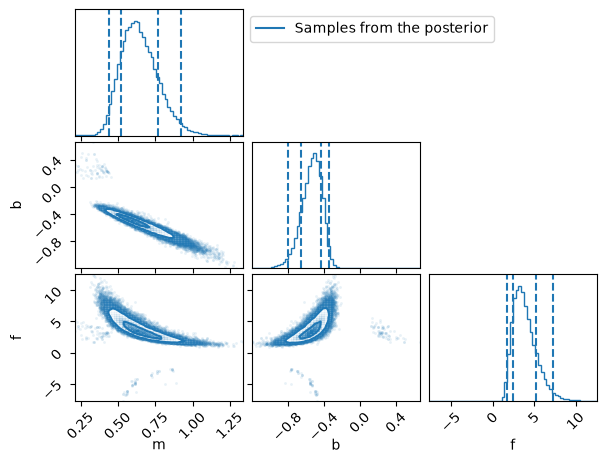

In [194]:
import corner

fig = plt.figure()
fig = corner.corner(
    chain,
    bins=60,
    labels=["m", "b", "f"],
    color="C0",
    levels=1-np.exp(-0.5*np.array([1, 2])**2), # Credible contours corresponding
    quantiles=[0.025, 0.16, 0.84, 0.975],
    fig=fig
);
fig.get_axes()[0].plot([], [], c="C0", label="Samples from the posterior")
fig.get_axes()[0].legend(loc=2, bbox_to_anchor=(1, 1))




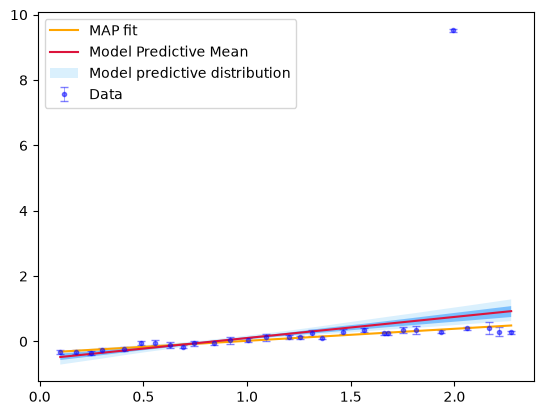

In [219]:
posterior_samples = chain[rng.choice(chain.shape[0], size=200)]

posterior_model_predictive = np.array([model(samples[0], samples[1], x) for samples in posterior_samples])

model_quantiles = np.quantile(
    posterior_model_predictive, q=[0.025, 0.16, 0.84, 0.975], axis=0
)

m_post = np.mean(chain[:,0])
b_post = np.mean(chain[:,1])

fig, ax = plt.subplots()

plt.errorbar(x, y, yerr=y_err, fmt=".", color="blue", capsize=3, elinewidth=0.5, label="Data", alpha=0.5)
ax.plot(x, model(m_MAP, b_MAP, x), c="orange", label="MAP fit")
ax.plot(x, model(m_post, b_post, x), c="crimson", label="Model Predictive Mean")
ax.fill_between(x, model_quantiles[0], model_quantiles[-1], alpha=0.3, facecolor="lightskyblue",
                label="Model predictive distribution")
ax.fill_between(x, model_quantiles[1], model_quantiles[-2], alpha=0.5, facecolor="dodgerblue")
ax.legend()





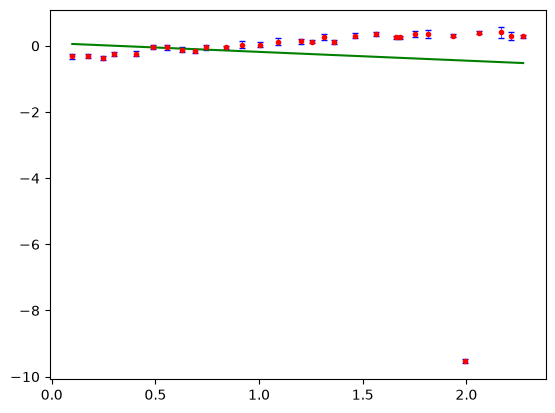

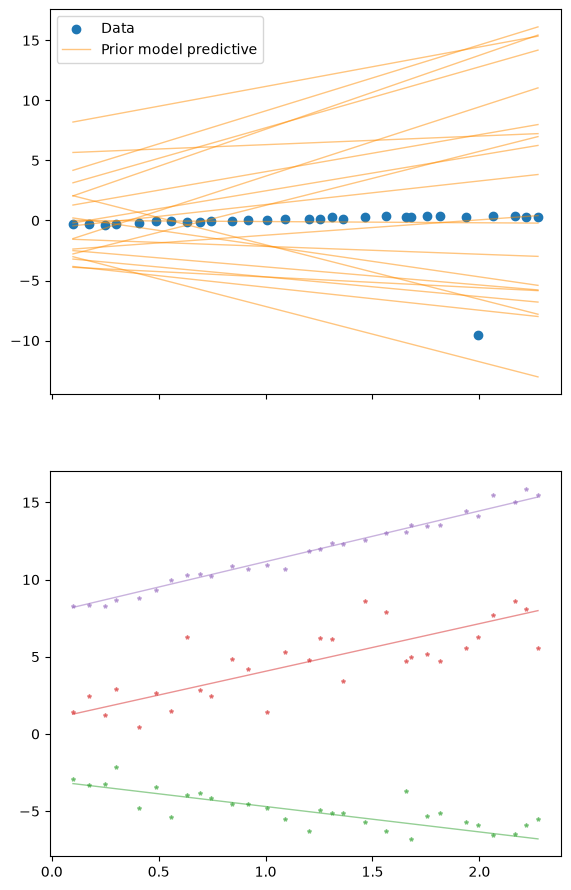

In [220]:
'''
DATA: data_2.txt
MODEL:  mu = m*x + b
        y_i ~ t(mu, nu, sigma)
'''



# Load different Data set
x, y, y_err = np.loadtxt('../lectures/data/linear_fits/data_2.txt', unpack=True)

m_RG2, b_RG2 = np.polyfit(x, y, 1)

fig, ax = plt.subplots(1,1)

ax.errorbar(x, y, y_err, ecolor='blue', capsize=2.5, elinewidth=0.5, fmt='.', c='red')
ax.plot(x, m_RG2*x + b_RG2, c='green', ls='-')



def log_likelihood_D2(parameters, x, y):
    m, b, nu, sigma = parameters

    prediction = model(m, b, x)

    residuals = y - prediction

    log_likelihood = np.sum(ss.t.logpdf(x=residuals, df=nu, loc=0, scale=sigma))

    return log_likelihood



# Priors
m_D2_prior = ss.norm(loc=1, scale=3)
b_D2_prior = ss.norm(loc=0, scale=3)
nu_D2_prior = ss.expon(loc=1, scale=29.0)      # nu > 1
sigma_D2_prior = ss.halfnorm(scale=1.0)        # sigma > 0 (residual scatter is ~0.08, so the prior must allow sigma < 1)




def log_prior(parameters):
    m, b, nu, sigma = parameters
    return (m_D2_prior.logpdf(m) + b_D2_prior.logpdf(b) + nu_D2_prior.logpdf(nu) + sigma_D2_prior.logpdf(sigma))


def sampling_prior(n_samples):
    return np.vstack((m_D2_prior.rvs(n_samples), b_D2_prior.rvs(n_samples), nu_D2_prior.rvs(n_samples), sigma_D2_prior.rvs(n_samples))).T


# samples = sampling_prior(20)
# print(samples)
# print(samples[:4, :2])

prior_samples = sampling_prior(n_samples=20)

pmp = np.array([model(*parameters, x) for parameters in prior_samples[:,:2]])

rng = np.random.default_rng(seed=42)

nu_samples = prior_samples[:,2]
sigma_samples = prior_samples[:,3]


ppd = np.array([ss.t.rvs(df=nu, loc=mu, scale=sigma) for nu, mu, sigma in zip(nu_samples, pmp, sigma_samples)])

#print(ppd)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.6, 11), sharex=True)

ax1.scatter(x,y, label='Data')
style = dict(c="darkorange", lw=1, alpha=0.5)
ax1.plot(x, pmp.T, **style)
ax1.plot([], [], label="Prior model predictive", **style)
ax1.legend();

ppd_style = dict(ls="none", marker="*", ms=5, alpha=0.5)

for i in range(3):
    ax2.plot(x, pmp[i], c=f"C{i+2}", **pmp_style)
    ax2.plot(x, ppd[i], c=f"C{i+2}", **pp_style)





Optimal m: 0.3678363474942636
Optimal b: -0.34842761066602074
Optimal nu: 1.0954742507300153
Optimal sigma: 0.04393904391133049


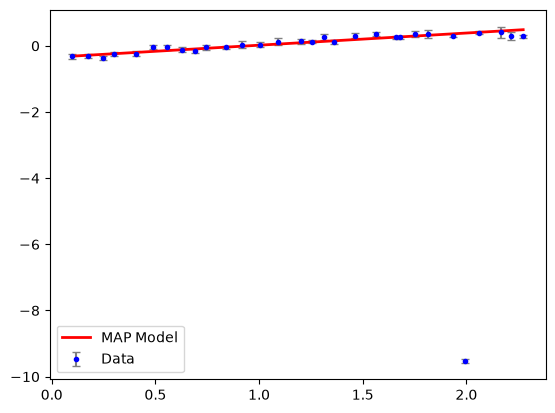

In [221]:
def log_posterior_D2(parameters, x ,y):
    log_post = log_likelihood_D2(parameters, x ,y) + log_prior(parameters)
    return -log_post

# Bounds required, because nu and sigma have restricted prior support

param_bounds = [
    (None, None),     # m: unrestricted
    (None, None),     # b: unrestricted
    (1.0001, None),   # nu: must be > 1, because of prior
    (1e-6, None)      # sigma: must be > 0, because of prior
]


MAP_D2_result = so.minimize(log_posterior_D2, x0=(1, 2, 6, 5), args=(x, y), method='L-BFGS-B', bounds=param_bounds, tol=1e-10)

m_MAP, b_MAP, nu_MAP, sigma_MAP = MAP_D2_result.x

print(f'Optimal m:', m_MAP)
print(f'Optimal b:', b_MAP)
print(f'Optimal nu:', nu_MAP)
print(f'Optimal sigma:', sigma_MAP)

fig, ax = plt.subplots(1,1)

ax.errorbar(x, y, y_err, ecolor='grey', capsize=3, fmt='.', c='blue', label="Data")
ax.plot(x, model(m_MAP, b_MAP, x), c='red', lw=2, label="MAP Model")
ax.legend();



In [222]:
import emcee

# emcee passes an array theta = [m, b, nu, sigma] and wants log p(theta | data).
# Use the Student-t posterior from above (NOT the old log_posterior(m, b, f, ...) from Exercise 1).
def log_posterior_wrapper(theta, x, y):
    lp = log_prior(theta)
    if not np.isfinite(lp):          # outside the prior support (nu <= 1 or sigma <= 0) -> reject
        return -np.inf
    return lp + log_likelihood_D2(theta, x, y)

# emcee requires some extra settings to run
n_param = 4       # Number of parameter we are sampling
n_walker = 32     # Number of walkers. This just needs to be 
                  # larger than 2*n_param + 1!
n_step = 5000     # How many steps each walker will take. The number
                  # of samples will be n_walker*n_step

# The starting point for each walker: a tiny ball around the MAP,
# so that every walker starts inside the prior support
theta_init = MAP_D2_result.x * (1 + 1e-3*np.random.normal(size=(n_walker, n_param)))

sampler = emcee.EnsembleSampler(
    nwalkers=n_walker, ndim=n_param,
    log_prob_fn=log_posterior_wrapper,
    args=(x, y)
)
state = sampler.run_mcmc(theta_init, nsteps=n_step)


# The samples will be correlated, this checks how correlated they are
# We will discuss this once we come to MCMC methods
print("Auto-correlation time:")
for name, value in zip(["m", "b", "nu", "sigma"], sampler.get_autocorr_time()):
    print(f"{name} = {value:.1f}")

# We need to discard the beginning of the chain (a few auto-correlation times)
# to get rid of the initial conditions
chain = sampler.get_chain(discard=500, thin=20, flat=True)

print("Posterior results (mean±std)")
for i, name in enumerate(["m", "b", "nu", "sigma"]):
    print(f"{name} = {np.mean(chain[:,i]):.3f}±{np.std(chain[:,i]):.3f}")


Auto-correlation time:
m = 46.7
b = 45.3
nu = 55.5
sigma = 56.4
Posterior results (mean±std)
m = 0.363±0.025
b = -0.338±0.031
nu = 1.499±0.389
sigma = 0.058±0.014


In [223]:

print("Posterior results (mean±std)")
for i, name in enumerate(["m", "b", "nu", "sigma"]):
    print(f"{name} = {np.mean(chain[:,i]):.3f}±{np.std(chain[:,i]):.3f}")

print('\1')
print('='*30)
print('\1')

print(f"m_MAP = {m_MAP:.3f}")
print(f"b_MAP = {b_MAP:.3f}")
print(f"nu_MAP = {nu_MAP:.3f}")
print(f"sigma_MAP = {sigma_MAP:.3f}")


sigma_post = np.mean(chain[:,3])
m_post = np.mean(chain[:,0])
b_post = np.mean(chain[:,1])




Posterior results (mean±std)
m = 0.363±0.025
b = -0.338±0.031
nu = 1.499±0.389
sigma = 0.058±0.014


m_MAP = 0.368
b_MAP = -0.348
nu_MAP = 1.095
sigma_MAP = 0.044


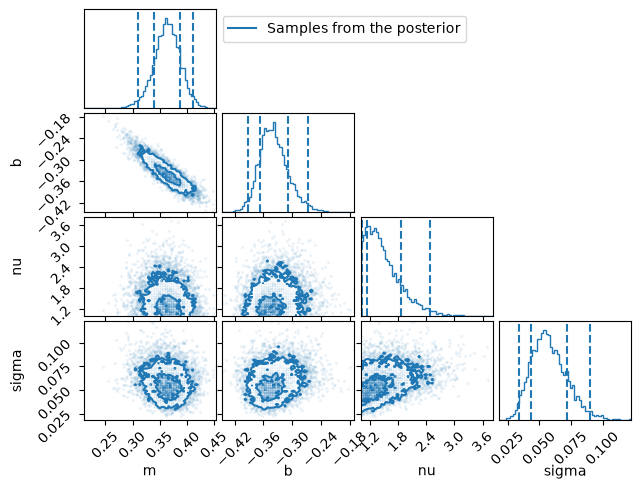

In [224]:
fig = plt.figure()
fig = corner.corner(
    chain,
    bins=60,
    labels=["m", "b", "nu", "sigma"],
    labelpad=0.15,
    color="C0",
    levels=1-np.exp(-0.5*np.array([1, 2])**2), # Credible contours corresponding
    quantiles=[0.025, 0.16, 0.84, 0.975],
    fig=fig
);
fig.get_axes()[0].plot([], [], c="C0", label="Samples from the posterior")
fig.get_axes()[0].legend(loc=2, bbox_to_anchor=(1, 1))



posterior_samples = chain[rng.choice(chain.shape[0], size=200)]

posterior_model_predictive = np.array([model(samples[0], samples[1], x) for samples in posterior_samples])


model_quantiles = np.quantile(
    posterior_model_predictive, q=[0.025, 0.16, 0.84, 0.975], axis=0
)


posterior_samples = chain[rng.choice(chain.shape[0], size=2000)]

mu = posterior_samples[:, 0, None]*x + posterior_samples[:, 1, None]

y_pred = mu + posterior_samples[:, 3, None] * ss.t.rvs(df=posterior_samples[:, 2, None], size=mu.shape)


# sigma_post = posterior_samples[:30,3]

# print(sigma_post)

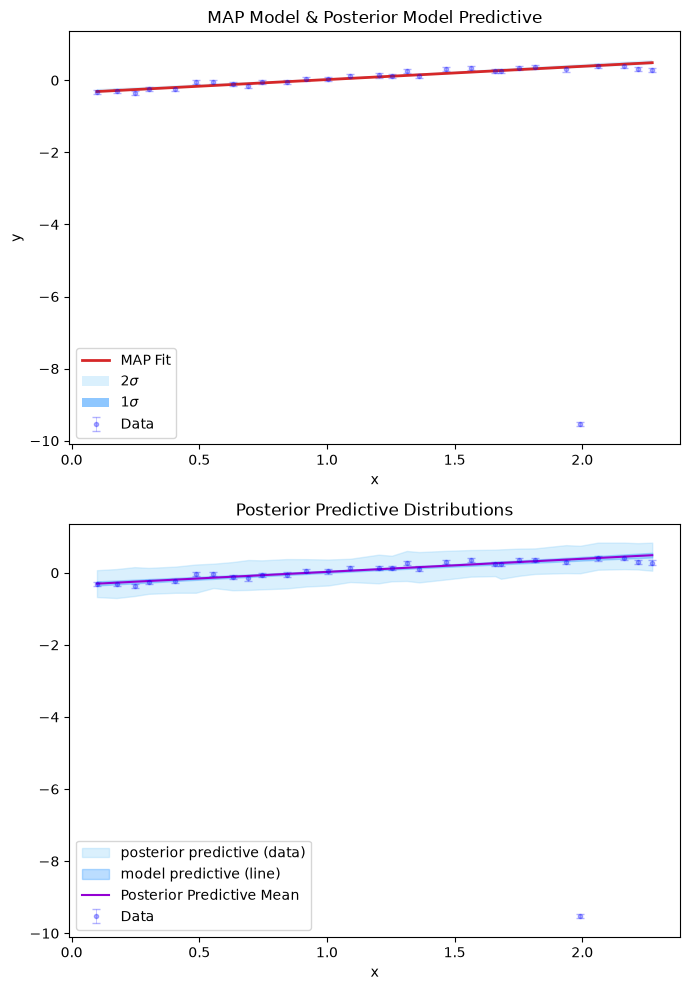

In [225]:
# t-student final plottery

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 10), sharey=True)

ax1.errorbar(x, y, yerr=sigma_post, fmt=".", capsize=3, color="blue", elinewidth=0.5, alpha=0.3, label="Data")
ax1.plot(x, model(m_MAP, b_MAP, x), lw=2, c="C3", label="MAP Fit")
ax1.fill_between(x, model_quantiles[0], model_quantiles[-1], alpha=0.3, facecolor="lightskyblue",
                 label=r"2$\sigma$")
ax1.fill_between(x, model_quantiles[1], model_quantiles[-2], alpha=0.5, facecolor="dodgerblue", label=r"1$\sigma$")

ax1.set_title("MAP Model & Posterior Model Predictive")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.legend()


ax2.errorbar(x, y, yerr=sigma_post, fmt=".", capsize=3, color="blue", elinewidth=0.5, alpha=0.3, label="Data")

for band, lbl, col in [(y_pred, "posterior predictive (data)", "lightskyblue"), 
                       (mu, "model predictive (line)", "dodgerblue")]:
    q = np.quantile(band, [0.025, 0.975], axis=0)
    ax2.fill_between(x, q[0], q[1], alpha=0.3, label=lbl, color=col)

ax2.plot(x, model(m_post, b_post, x), c="darkviolet", label="Posterior Predictive Mean")
ax2.set_title("Posterior Predictive Distributions")
ax2.set_xlabel("x")
ax2.legend()

plt.tight_layout()
plt.show()

# Exercise 2

The data in the previous example were a synthetic version of real observations that were obtained in an AstroWoche project in 2024 by Jonas Spiller, Theo Lequy, Clara Bleich. 

<!-- ![jovian moons data](../assets/jovian_moons_raw_data.png) -->
<img style="display: block; 
    margin-left: auto;
    margin-right: auto;
    width: 60%;"
    src="../assets/jovian_moons_raw_data.png" alt="jovian moons data"/>

The real observations can be found in `data/jovian_moons/{moon}.dat`:

In [14]:
# moon = "Io"

# t, distance, distance_alt, distance_err = np.loadtxt(
#     f"./data/jovian_moons/{moon}.dat", unpack=True)

1. Repeat the analysis with the real data set. What do you find?

There is another distance estimate provided. The difference between the distance estimates comes from different approaches to converting the measured distance between Jupiter and its moons from the number of pixels to a physical distance in km.

2. How does the analysis look when using this other distance estimate (what I call `distance_alt`)? What about the other moons?



Because there are two distance estimates that do not agree, both of which are based on reasonable approaches, this suggests that there might be a _systematic_ error in the measurements. Systematic errors are usually not random (which means they do not get smaller as you obtain more data). But we could pretend the offset between the two measurements is an estimate of an unaccounted statistical uncertainty. 

3. How does the analysis look when we assume `sigma_d**2 = distance_err**2 + (distance - distance_alt)**2`?



4. Instead of assuming that the uncertainty is underestimated by this offset, we can also model it. Does the model work better if the variance is a free parameter?
